In [1]:

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Database path
db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

# Output folder
output_dir = Path("stage20_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Load selected yield training data
with sqlite3.connect(db_path) as conn:
    data = pd.read_sql_query(
        "SELECT * FROM agri_yield_train_selected",
        conn
    )

print("Dataset shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

print("\nFirst five rows:")
display(data.head())

print("\nMissing values:")
display(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())


Dataset shape: (10000, 11)

Columns:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall', 'yield']

First five rows:


,NDVI_Temperature,OrganicMatter_Sand,Temperature_Rainfall,sand_pct,NDVI_Rainfall,soil_ph,organic_matter,Humidity_Rainfall,Temperature_Humidity,rainfall,yield
0,11.592,110.656,2777.04,41.6,50.692,6.25,2.66,7714.0,1764.0,110.2,4105.8
1,15.871,147.132,3397.47,40.2,74.517,6.70,3.66,9851.4,2098.2,126.3,4247.8
2,17.664,138.000,3019.44,40.0,70.016,7.21,3.45,7220.4,1821.6,109.4,4021.8
3,18.352,141.112,4596.88,56.9,96.286,5.73,2.48,12268.7,2338.4,155.3,4326.8
4,15.500,110.466,4315.00,30.6,107.012,6.88,3.61,13808.0,2000.0,172.6,3708.0



Missing values:


NDVI_Temperature        0
OrganicMatter_Sand      0
Temperature_Rainfall    0
sand_pct                0
NDVI_Rainfall           0
soil_ph                 0
organic_matter          0
Humidity_Rainfall       0
Temperature_Humidity    0
rainfall                0
yield                   0
dtype: int64


Duplicate rows: 0


In [2]:

features = [
    "NDVI_Temperature",
    "OrganicMatter_Sand",
    "Temperature_Rainfall",
    "sand_pct",
    "NDVI_Rainfall",
    "soil_ph",
    "organic_matter",
    "Humidity_Rainfall",
    "Temperature_Humidity",
    "rainfall"
]

target = "yield"

# Check that the required columns exist
required_columns = features + [target]
missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}"
    )

# Select features and target
X = data[features].copy()
y = data[target].copy()

# Convert values to numeric and handle invalid values
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")

# Remove rows with missing target values
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Replace infinite values and impute missing feature values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

if X.isnull().any().any():
    raise ValueError("Some feature columns could not be imputed.")

if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Features contain infinite or invalid values.")

if not np.isfinite(y.to_numpy()).all():
    raise ValueError("Target contains infinite or invalid values.")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget statistics:")
display(y.describe())

print("\nFeatures used:")
print(X.columns.tolist())


Feature shape: (10000, 10)
Target shape: (10000,)

Target statistics:


count    10000.000000
mean      4251.976400
std        436.533109
min       3500.200000
25%       3868.050000
50%       4257.150000
75%       4638.325000
max       5000.000000
Name: yield, dtype: float64


Features used:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall']


In [3]:

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),

    "Tuned Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Tuned Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        random_state=42
    )
}

# Store actual values and out-of-fold predictions
predictions = pd.DataFrame({
    "Actual_Yield": y.to_numpy()
})

for model_name, model in models.items():
    print("Generating predictions for:", model_name)

    oof_predictions = cross_val_predict(
        model,
        X,
        y,
        cv=cv,
        n_jobs=-1
    )

    column_name = model_name.replace(" ", "_").replace("-", "_")
    predictions[column_name] = oof_predictions

print("\nPrediction preview:")
display(predictions.head())

print("\nPrediction columns:")
print(predictions.columns.tolist())


Generating predictions for: Dummy Regressor
Generating predictions for: Tuned Random Forest
Generating predictions for: Tuned Gradient Boosting

Prediction preview:


,Actual_Yield,Dummy_Regressor,Tuned_Random_Forest,Tuned_Gradient_Boosting
0,4105.8,4250.802975,4214.044165,4240.498488
1,4247.8,4252.844475,4238.673809,4249.271192
2,4021.8,4254.755588,4260.743185,4236.708550
3,4326.8,4250.802975,4314.948785,4262.461872
4,3708.0,4252.844475,4294.793268,4269.527491



Prediction columns:
['Actual_Yield', 'Dummy_Regressor', 'Tuned_Random_Forest', 'Tuned_Gradient_Boosting']


In [4]:

results = []

prediction_columns = {
    "Dummy Regressor": "Dummy_Regressor",
    "Tuned Random Forest": "Tuned_Random_Forest",
    "Tuned Gradient Boosting": "Tuned_Gradient_Boosting"
}

for model_name, pred_col in prediction_columns.items():
    actual = predictions["Actual_Yield"]
    predicted = predictions[pred_col]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

metrics_df = pd.DataFrame(results).sort_values("MAE")

display(metrics_df.round(4))

metrics_df.to_csv(
    output_dir / "stage20_overall_metrics.csv",
    index=False
)

print("Saved overall metrics.")


,Model,MAE,RMSE,R2
0,Dummy Regressor,378.8920,436.5463,-0.0002
2,Tuned Gradient Boosting,378.9967,436.8325,-0.0015
1,Tuned Random Forest,379.8035,438.3206,-0.0083


Saved overall metrics.


In [5]:

error_data = predictions.copy()

for model_name, pred_col in prediction_columns.items():
    prefix = model_name.replace(" ", "_").replace("-", "_")

    # Actual minus predicted
    error_data[f"{prefix}_Residual"] = (
        error_data["Actual_Yield"] - error_data[pred_col]
    )

    # Absolute error
    error_data[f"{prefix}_Absolute_Error"] = (
        error_data[f"{prefix}_Residual"].abs()
    )

print("Error table preview:")
display(error_data.head())

error_data.to_csv(
    output_dir / "stage20_row_level_errors.csv",
    index=False
)

print("Saved row-level errors.")


Error table preview:


,Actual_Yield,Dummy_Regressor,Tuned_Random_Forest,Tuned_Gradient_Boosting,Dummy_Regressor_Residual,Dummy_Regressor_Absolute_Error,Tuned_Random_Forest_Residual,Tuned_Random_Forest_Absolute_Error,Tuned_Gradient_Boosting_Residual,Tuned_Gradient_Boosting_Absolute_Error
0,4105.8,4250.802975,4214.044165,4240.498488,-145.002975,145.002975,-108.244165,108.244165,-134.698488,134.698488
1,4247.8,4252.844475,4238.673809,4249.271192,-5.044475,5.044475,9.126191,9.126191,-1.471192,1.471192
2,4021.8,4254.755588,4260.743185,4236.708550,-232.955588,232.955588,-238.943185,238.943185,-214.908550,214.908550
3,4326.8,4250.802975,4314.948785,4262.461872,75.997025,75.997025,11.851215,11.851215,64.338128,64.338128
4,3708.0,4252.844475,4294.793268,4269.527491,-544.844475,544.844475,-586.793268,586.793268,-561.527491,561.527491


Saved row-level errors.


In [6]:

error_data["Yield_Range"] = pd.qcut(
    error_data["Actual_Yield"],
    q=5,
    duplicates="drop"
)

range_results = []

for yield_range, group in error_data.groupby(
    "Yield_Range",
    observed=True
):
    for model_name, pred_col in prediction_columns.items():
        prefix = model_name.replace(" ", "_").replace("-", "_")

        residual_col = f"{prefix}_Residual"
        absolute_error_col = f"{prefix}_Absolute_Error"

        range_results.append({
            "Yield_Range": str(yield_range),
            "Model": model_name,
            "Observations": len(group),
            "Mean_Actual_Yield": group["Actual_Yield"].mean(),
            "Mean_Predicted_Yield": group[pred_col].mean(),
            "MAE": group[absolute_error_col].mean(),
            "RMSE": np.sqrt(
                mean_squared_error(
                    group["Actual_Yield"],
                    group[pred_col]
                )
            ),
            "Mean_Residual": group[residual_col].mean()
        })

range_metrics = pd.DataFrame(range_results)

display(range_metrics.round(3))

range_metrics.to_csv(
    output_dir / "stage20_error_by_yield_range.csv",
    index=False
)

print("Saved error-by-range analysis.")


,Yield_Range,Model,Observations,Mean_Actual_Yield,Mean_Predicted_Yield,MAE,RMSE,Mean_Residual
0,"(3500.1989999999996, 3794.64]",Dummy Regressor,2000,3647.291,4251.990,604.699,610.734,-604.699
1,"(3500.1989999999996, 3794.64]",Tuned Random Forest,2000,3647.291,4251.585,604.294,611.857,-604.294
2,"(3500.1989999999996, 3794.64]",Tuned Gradient Boosting,2000,3647.291,4251.438,604.147,610.550,-604.147
3,"(3794.64, 4100.62]",Dummy Regressor,2000,3945.267,4252.027,306.760,319.198,-306.760
4,"(3794.64, 4100.62]",Tuned Random Forest,2000,3945.267,4252.525,307.258,322.762,-307.258
5,"(3794.64, 4100.62]",Tuned Gradient Boosting,2000,3945.267,4252.121,306.854,319.963,-306.854
6,"(4100.62, 4404.1]",Dummy Regressor,2001,4255.891,4252.004,75.393,87.437,3.887
7,"(4100.62, 4404.1]",Tuned Random Forest,2001,4255.891,4252.266,80.695,96.764,3.625
8,"(4100.62, 4404.1]",Tuned Gradient Boosting,2001,4255.891,4251.700,76.422,89.467,4.191
9,"(4404.1, 4708.72]",Dummy Regressor,1999,4558.279,4251.901,306.378,319.244,306.378


Saved error-by-range analysis.


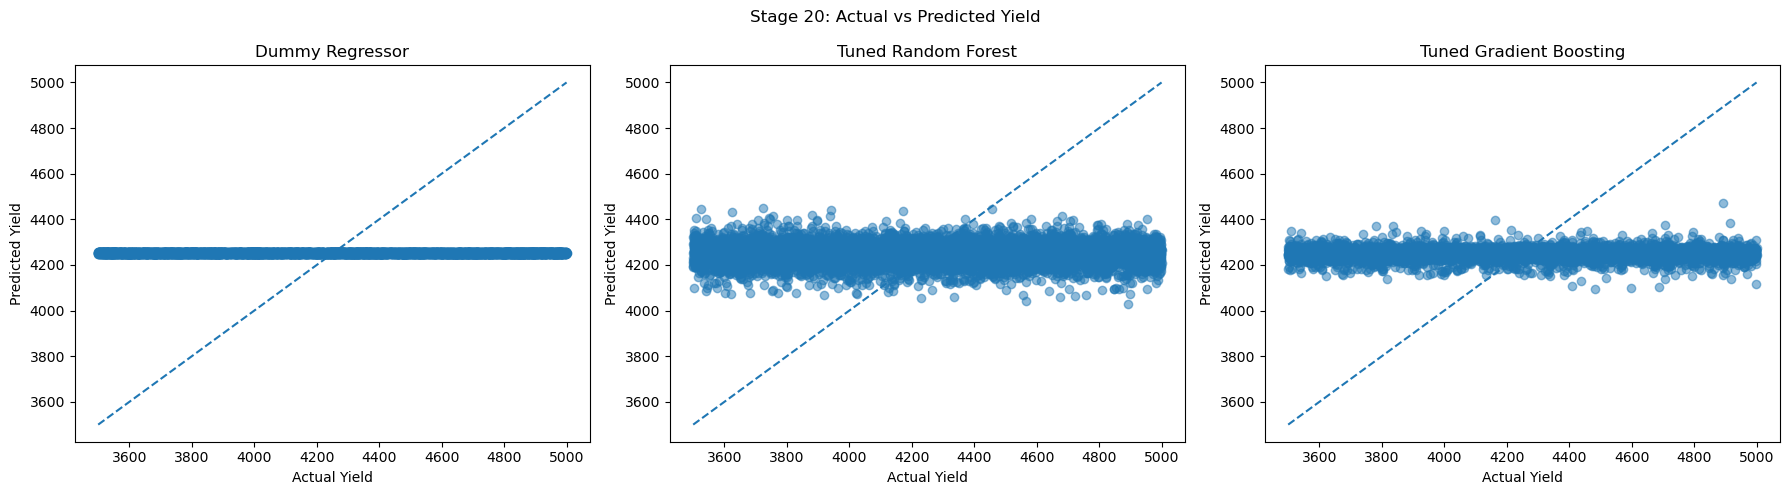

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, pred_col) in zip(
    axes,
    prediction_columns.items()
):
    ax.scatter(
        predictions["Actual_Yield"],
        predictions[pred_col],
        alpha=0.5
    )

    # Ideal predictions lie on this line
    min_value = min(
        predictions["Actual_Yield"].min(),
        predictions[pred_col].min()
    )
    max_value = max(
        predictions["Actual_Yield"].max(),
        predictions[pred_col].max()
    )

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual Yield")
    ax.set_ylabel("Predicted Yield")

plt.suptitle("Stage 20: Actual vs Predicted Yield")
plt.tight_layout()
plt.savefig(
    output_dir / "stage20_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


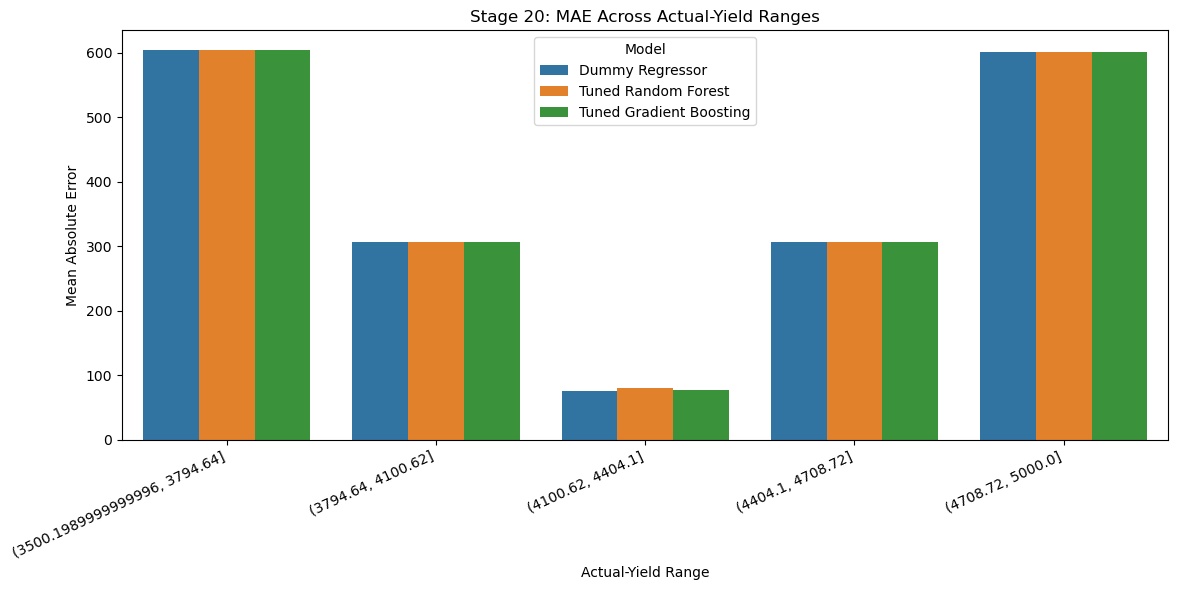

In [8]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=range_metrics,
    x="Yield_Range",
    y="MAE",
    hue="Model"
)

plt.title("Stage 20: MAE Across Actual-Yield Ranges")
plt.xlabel("Actual-Yield Range")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    output_dir / "stage20_mae_by_yield_range.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [9]:

bias_results = []

for model_name, pred_col in prediction_columns.items():
    prefix = model_name.replace(" ", "_").replace("-", "_")
    residual_col = f"{prefix}_Residual"

    residuals = error_data[residual_col]

    bias_results.append({
        "Model": model_name,
        "Mean_Residual": residuals.mean(),
        "Underpredicted_Observations": (residuals > 0).sum(),
        "Overpredicted_Observations": (residuals < 0).sum(),
        "Exact_Predictions": (residuals == 0).sum(),
        "Mean_Absolute_Error": residuals.abs().mean()
    })

bias_df = pd.DataFrame(bias_results)

display(bias_df.round(4))

bias_df.to_csv(
    output_dir / "stage20_over_under_prediction.csv",
    index=False
)

print("Saved overprediction and underprediction analysis.")


,Model,Mean_Residual,Underpredicted_Observations,Overpredicted_Observations,Exact_Predictions,Mean_Absolute_Error
0,Dummy Regressor,0.0000,5041,4959,0,378.8920
1,Tuned Random Forest,-0.2392,5049,4951,0,379.8035
2,Tuned Gradient Boosting,0.1428,5044,4956,0,378.9967


Saved overprediction and underprediction analysis.


In [10]:

worst_error_tables = {}

for model_name, pred_col in prediction_columns.items():
    prefix = model_name.replace(" ", "_").replace("-", "_")
    error_col = f"{prefix}_Absolute_Error"
    residual_col = f"{prefix}_Residual"

    worst_errors = error_data.nlargest(
        20,
        error_col
    )[
        [
            "Actual_Yield",
            pred_col,
            residual_col,
            error_col
        ]
    ].copy()

    worst_error_tables[model_name] = worst_errors

    filename = (
        "stage20_largest_errors_"
        + prefix.lower()
        + ".csv"
    )

    worst_errors.to_csv(
        output_dir / filename,
        index=False
    )

    print(f"\n20 largest errors: {model_name}")
    display(worst_errors.head(10))

print("Saved the largest-error tables.")



20 largest errors: Dummy Regressor


,Actual_Yield,Dummy_Regressor,Dummy_Regressor_Residual,Dummy_Regressor_Absolute_Error
5882,3500.3,4254.755588,-754.455588,754.455588
112,3500.8,4254.755588,-753.955588,753.955588
5666,3501.3,4254.755588,-753.455588,753.455588
2670,3501.7,4254.755588,-753.055588,753.055588
9539,3500.2,4252.844475,-752.644475,752.644475
8917,3502.8,4254.755588,-751.955588,751.955588
7249,3503.2,4254.755588,-751.555588,751.555588
5936,3500.7,4252.167050,-751.467050,751.467050
1012,3501.5,4252.844475,-751.344475,751.344475
2778,3503.6,4254.755588,-751.155588,751.155588



20 largest errors: Tuned Random Forest


,Actual_Yield,Tuned_Random_Forest,Tuned_Random_Forest_Residual,Tuned_Random_Forest_Absolute_Error
2129,3524.1,4444.580651,-920.480651,920.480651
3658,3509.3,4406.104144,-896.804144,896.804144
4263,4891.6,4028.734497,862.865503,862.865503
5516,4981.9,4121.443903,860.456097,860.456097
8214,3541.8,4401.438617,-859.638617,859.638617
5561,4989.8,4132.047862,857.752138,857.752138
8768,4952.0,4096.091817,855.908183,855.908183
4007,3501.5,4353.034364,-851.534364,851.534364
9118,3509.2,4347.512474,-838.312474,838.312474
6447,3503.6,4339.886570,-836.286570,836.286570



20 largest errors: Tuned Gradient Boosting


,Actual_Yield,Tuned_Gradient_Boosting,Tuned_Gradient_Boosting_Residual,Tuned_Gradient_Boosting_Absolute_Error
5069,4998.5,4118.412263,880.087737,880.087737
3658,3509.3,4346.973843,-837.673843,837.673843
2670,3501.7,4309.305699,-807.605699,807.605699
5274,4967.8,4161.275436,806.524564,806.524564
4267,3507.0,4306.990562,-799.990562,799.990562
8214,3541.8,4338.811862,-797.011862,797.011862
6989,4999.6,4204.825723,794.774277,794.774277
5516,4981.9,4193.664708,788.235292,788.235292
6322,3530.5,4314.981635,-784.481635,784.481635
3665,3510.3,4293.558799,-783.258799,783.258799


Saved the largest-error tables.


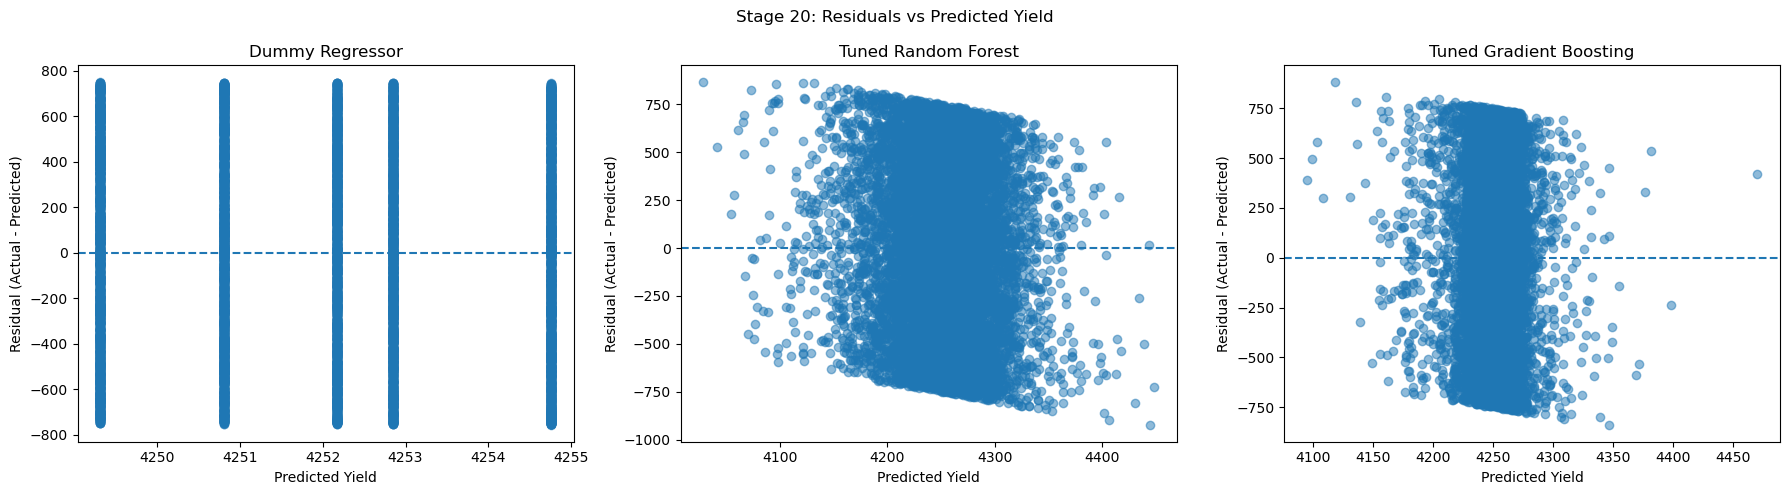

In [11]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, pred_col) in zip(
    axes,
    prediction_columns.items()
):
    prefix = model_name.replace(" ", "_").replace("-", "_")
    residual_col = f"{prefix}_Residual"

    ax.scatter(
        predictions[pred_col],
        error_data[residual_col],
        alpha=0.5
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Yield")
    ax.set_ylabel("Residual (Actual - Predicted)")

plt.suptitle("Stage 20: Residuals vs Predicted Yield")
plt.tight_layout()

plt.savefig(
    output_dir / "stage20_residuals_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [12]:

best_mae_row = metrics_df.loc[metrics_df["MAE"].idxmin()]
best_rmse_row = metrics_df.loc[metrics_df["RMSE"].idxmin()]
best_r2_row = metrics_df.loc[metrics_df["R2"].idxmax()]

print("STAGE 20 — RESULTS SUMMARY")
print("-" * 45)

print(
    f"Lowest MAE: {best_mae_row['Model']} "
    f"({best_mae_row['MAE']:.4f})"
)

print(
    f"Lowest RMSE: {best_rmse_row['Model']} "
    f"({best_rmse_row['RMSE']:.4f})"
)

print(
    f"Highest R²: {best_r2_row['Model']} "
    f"({best_r2_row['R2']:.4f})"
)

print("\nMean residual by model:")

for model_name, pred_col in prediction_columns.items():
    prefix = model_name.replace(" ", "_").replace("-", "_")
    residual_col = f"{prefix}_Residual"

    print(
        f"{model_name}: "
        f"{error_data[residual_col].mean():.4f}"
    )

print("\nOutputs saved in:", output_dir.resolve())
print("Remember: these results are exploratory, not an independent final test.")


STAGE 20 — RESULTS SUMMARY
---------------------------------------------
Lowest MAE: Dummy Regressor (378.8920)
Lowest RMSE: Dummy Regressor (436.5463)
Highest R²: Dummy Regressor (-0.0002)

Mean residual by model:
Dummy Regressor: 0.0000
Tuned Random Forest: -0.2392
Tuned Gradient Boosting: 0.1428

Outputs saved in: C:\Users\ADMIN\smart agricultural analytics\stage20_outputs
Remember: these results are exploratory, not an independent final test.


In [13]:

print("STAGE 20 OUTPUT FILES")
print("=" * 40)

for file in sorted(output_dir.iterdir()):
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size:,} bytes")


STAGE 20 OUTPUT FILES
stage20_actual_vs_predicted.png — 506,320 bytes
stage20_error_by_yield_range.csv — 2,137 bytes
stage20_largest_errors_dummy_regressor.csv — 1,223 bytes
stage20_largest_errors_tuned_gradient_boosting.csv — 1,359 bytes
stage20_largest_errors_tuned_random_forest.csv — 1,349 bytes
stage20_mae_by_yield_range.png — 226,760 bytes
stage20_over_under_prediction.csv — 325 bytes
stage20_overall_metrics.csv — 256 bytes
stage20_residuals_vs_predicted.png — 1,252,559 bytes
stage20_row_level_errors.csv — 1,685,599 bytes
